# Fisheye Visual Odometry

Implement a visual odometry pipeline for fisheye drone footage that tracks features with Lucas–Kanade flow and recovers a relative camera trajectory.

This notebook only provides **data paths** and **trajectory evaluation**. The pipeline itself is up to you.

**Deliverables** (all in this notebook):
- Recovered relative trajectory, compared against GT with the evaluation cells below
- All code cells run and plots rendered
- Overlay video
- Summary markdown cell at the end: implementation choices, parameter tuning, observed trajectory quality

In [2]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

from pose_helpers import (
    TrajectoryResult,
    TrajectoryVideoWriter,
    analyze_trajectory,
    draw_tracks,
    plot_trajectory,
    write_video_with_trajectory,
)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11

In [3]:
# --- Data paths ---
ROOT = Path("./")
DATA_ROOT = Path("./flight")
VIDEO_PATH = DATA_ROOT / "recording.mp4"
CALIBRATION_PATH = ROOT / "calibration-params.json"
GT_PATH = ROOT / "./flight_trajectory_coordinates.csv"

# --- Outputs ---
OVERLAY_VIDEO_PATH = Path("tracks_overlay.mp4")              # written by your pipeline: frames with your tracked points
TRAJECTORY_VIDEO_PATH = Path("tracks_with_trajectory.mp4")   # written by the evaluation: your overlay + trajectory plot

for p in (VIDEO_PATH, CALIBRATION_PATH, GT_PATH):
    if not p.exists():
        raise FileNotFoundError(p)

print(f"Video       : {VIDEO_PATH}")
print(f"Calibration : {CALIBRATION_PATH}")
print(f"Ground truth: {GT_PATH}")

Video       : flight/recording.mp4
Calibration : calibration-params.json
Ground truth: flight_trajectory_coordinates.csv


## Your pipeline

Add as many cells as you need. The evaluation below expects two things.

**1. A `traj_result: TrajectoryResult`** with:

| Field | Shape | Meaning |
| :-- | :-- | :-- |
| `positions` | `(N + 1, ≥2)` array | Row 0 is the starting pose; row `i + 1` is the pose at `frame_indices[i]`. Only X and Y are evaluated. |
| `frame_indices` | `N` ints | Absolute frame index in `recording.mp4` of each recovered pose (used to match GT rows). |
| `inliers` | `N` ints | Inlier count of the motion estimate for each recovered pose. |
| `timestamps` | `N` floats | Time of each recovered pose, in seconds. |

**2. An overlay video at `OVERLAY_VIDEO_PATH`** with one frame per frame of `recording.mp4`, in the same order (frame `k` of the overlay = frame `k` of the recording). `write_video_with_trajectory` seeks into it by `frame_indices`. `TrajectoryVideoWriter` and `draw_tracks` from `pose_helpers` can do this for you.

### Step 1: Feature tracking

1. Load the fisheye (Kannala–Brandt) calibration into `K` and `D`.
2. Detect Shi–Tomasi corners on a grid inside the fisheye image circle, so points are spread over the whole view.
3. Track them frame to frame with pyramidal Lucas–Kanade and a forward–backward consistency check. Drop lost tracks and top up with new corners when too few remain.
4. Draw the tracks on a few frames as a sanity check.

**Hand-off:** `track_pairs`, a list with one entry per pair of neighbouring frames `(k-1, k)`:

| Key | Type | Meaning |
| :-- | :-- | :-- |
| `prev_idx`, `curr_idx` | int | frame indices `k-1`, `k` |
| `timestamp` | float | time of frame `k`, in seconds |
| `pts_prev` | `(N, 2)` float32 | pixel positions in frame `k-1` |
| `pts_curr` | `(N, 2)` float32 | the same points in frame `k` |
| `track_ids` | `(N,)` int | ID of each track, stable across frames |

`undistort_to_normalized(pts)` converts pixels into undistorted normalized camera coordinates for the pose step.

# Fisheye calibration + corner tracking

In [8]:
import json
from collections import deque
from tqdm.auto import tqdm

with open(CALIBRATION_PATH) as f:
    cam = json.load(f)["cameras"][0]

assert cam["model"] == "kannala-brandt4", f"Unexpected camera model: {cam['model']}"

K = np.array(
    [
        [cam["focalLengthX"], 0.0, cam["principalPointX"]],
        [0.0, cam["focalLengthY"], cam["principalPointY"]],
        [0.0, 0.0, 1.0],
    ],
    dtype=np.float64,
)
D = np.array(cam["distortionCoefficients"], dtype=np.float64).reshape(4, 1)
IMG_W, IMG_H = cam["imageWidth"], cam["imageHeight"]


def undistort_to_normalized(pts: np.ndarray) -> np.ndarray:
    """Distorted pixel coords (N, 2) -> undistorted normalized camera coords (N, 2), i.e. focal length 1."""
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 1, 2)
    return cv.fisheye.undistortPoints(pts, K, D).reshape(-1, 2)


print("K =\n", K)
print("D =", D.ravel())
print(f"Image size: {IMG_W}x{IMG_H}")

K =
 [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
D = [-0.03678765  0.00404803 -0.00777366  0.00206872]
Image size: 1920x1080


In [15]:
# --- Tracking parameters (all in one place) ---
GRID = (8, 5)              # (cols, rows) of detection cells; keeps features spread over the image
MAX_PER_CELL = 15          # target number of tracked points per cell
MIN_PER_CELL = 3           # top up a cell once it falls below this...
MIN_TRACKS = 300           # ...or once the total falls below this

GFTT_PARAMS = dict(qualityLevel=0.01, minDistance=15, blockSize=7)
LK_PARAMS = dict(
    winSize=(21, 21),
    maxLevel=4,
    criteria=(cv.TERM_CRITERIA_EPS | cv.TERM_CRITERIA_COUNT, 30, 0.01),
)
FB_THRESH = 1.0            # max forward-backward error [px]
CIRCLE_MARGIN = 20         # px kept away from the fisheye image-circle edge
TRAIL_LEN = 15             # trail length (frames) drawn in the snapshots
SNAPSHOT_FRAMES = [50, 900, 1800, 2700, 3500]

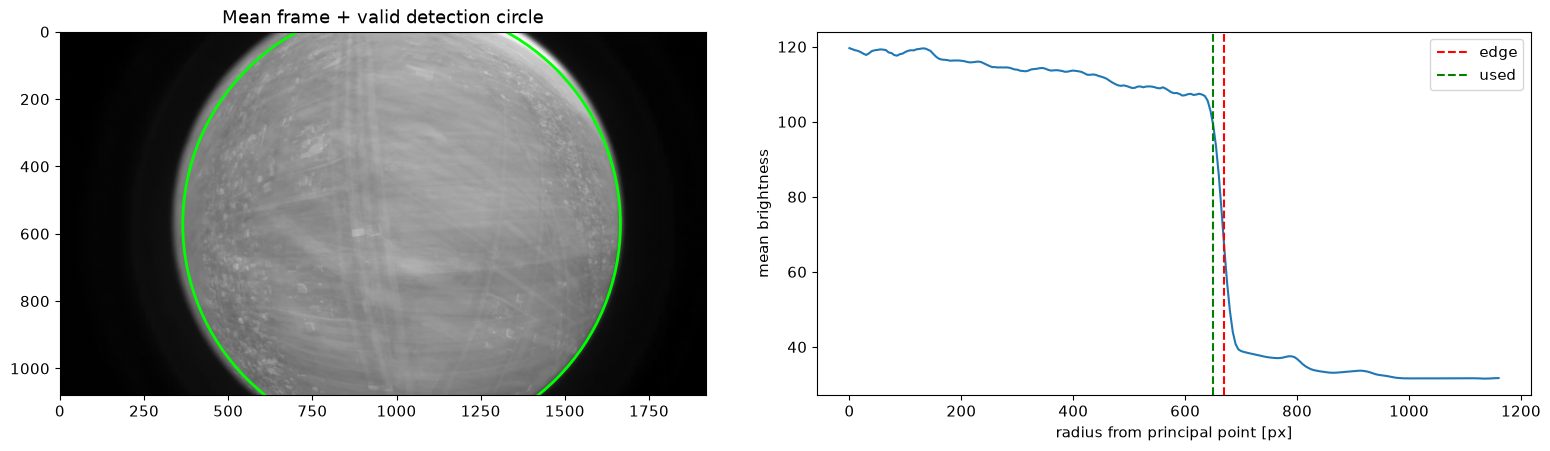

In [9]:
cap = cv.VideoCapture(str(VIDEO_PATH))
n_frames_total = int(cap.get(cv.CAP_PROP_FRAME_COUNT))
mean_img = np.zeros((IMG_H, IMG_W), np.float64)
sample_idx = np.linspace(0, n_frames_total - 1, 10).astype(int)

for i in sample_idx:
    cap.set(cv.CAP_PROP_POS_FRAMES, int(i))
    ok, frame = cap.read()
    assert ok, f"Cannot read frame {i}"
    mean_img += cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
mean_img /= len(sample_idx)
cap.release()

cx, cy = K[0, 2], K[1, 2]
yy, xx = np.mgrid[:IMG_H, :IMG_W]

radius_map = np.hypot(xx - cx, yy - cy)
radii = np.arange(0, int(radius_map.max()), 5)
ring_mean = np.array([mean_img[(radius_map >= r) & (radius_map < r + 5)].mean() for r in radii])

inside, outside = np.median(ring_mean[: len(ring_mean) // 3]), ring_mean[-1]
edge_radius = radii[np.argmax(ring_mean < (inside + outside) / 2)]
valid_radius = edge_radius - CIRCLE_MARGIN

valid_mask = (radius_map < valid_radius).astype(np.uint8) * 255

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].imshow(mean_img, cmap="gray")
axes[0].add_patch(plt.Circle((cx, cy), valid_radius, fill=False, color="lime", lw=2))
axes[0].set_title("Mean frame + valid detection circle")
axes[1].plot(radii, ring_mean)
axes[1].axvline(edge_radius, color="r", ls="--", label="edge")
axes[1].axvline(valid_radius, color="g", ls="--", label="used")
axes[1].set_xlabel("radius from principal point [px]")
axes[1].set_ylabel("mean brightness")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:

cell_w = IMG_W / GRID[0]
cell_h = IMG_H / GRID[1]


def cell_index(pts: np.ndarray) -> np.ndarray:
    """Flat grid-cell index for each (x, y) point."""
    cx_ = np.clip((pts[:, 0] // cell_w).astype(int), 0, GRID[0] - 1)
    cy_ = np.clip((pts[:, 1] // cell_h).astype(int), 0, GRID[1] - 1)
    return cy_ * GRID[0] + cx_

cell_valid_frac = np.array(
    [
        valid_mask[int(r * cell_h): int((r + 1) * cell_h), int(c * cell_w): int((c + 1) * cell_w)].mean() / 255
        for r in range(GRID[1])
        for c in range(GRID[0])
    ]
)
ACTIVE_CELLS = cell_valid_frac > 0.05

CELL_TARGET = np.ceil(MAX_PER_CELL * cell_valid_frac).astype(int)

def needs_topup(pts: np.ndarray) -> bool:
    if len(pts) < MIN_TRACKS:
        return True
    counts = np.bincount(cell_index(pts), minlength=GRID[0] * GRID[1])
    low = counts < np.minimum(MIN_PER_CELL, CELL_TARGET)
    return bool(np.any(low & ACTIVE_CELLS))


def detect_features(gray: np.ndarray, existing_pts: np.ndarray) -> np.ndarray:
    """Add Shi-Tomasi corners cell by cell, filling each grid cell up to its target count.

    New corners are kept at least minDistance away from already-tracked points.
    Returns only the NEW points, shape (M, 2) float32.
    """
    mask = valid_mask.copy()
    min_dist = GFTT_PARAMS["minDistance"]
    for x, y in existing_pts:
        cv.circle(mask, (int(round(x)), int(round(y))), min_dist, 0, -1)

    counts = (
        np.bincount(cell_index(existing_pts), minlength=GRID[0] * GRID[1])
        if len(existing_pts)
        else np.zeros(GRID[0] * GRID[1], int)
    )
    new_pts = []
    for r in range(GRID[1]):
        for c in range(GRID[0]):
            ci = r * GRID[0] + c
            want = CELL_TARGET[ci] - counts[ci]
            if not ACTIVE_CELLS[ci] or want <= 0:
                continue
            x0, x1 = int(c * cell_w), int((c + 1) * cell_w)
            y0, y1 = int(r * cell_h), int((r + 1) * cell_h)
            corners = cv.goodFeaturesToTrack(
                gray[y0:y1, x0:x1], maxCorners=int(want), mask=mask[y0:y1, x0:x1], **GFTT_PARAMS
            )
            if corners is not None:
                new_pts.append(corners.reshape(-1, 2) + (x0, y0))
    if not new_pts:
        return np.empty((0, 2), np.float32)
    return np.concatenate(new_pts).astype(np.float32)


def track_lk(prev_gray: np.ndarray, curr_gray: np.ndarray, prev_pts: np.ndarray):
    """Pyramidal LK with forward-backward check.

    Returns (p1, keep): p1 (N, 2) tracked positions, keep (N,) bool of reliable tracks.
    """
    if len(prev_pts) == 0:
        return np.empty((0, 2), np.float32), np.zeros(0, bool)
    p0 = prev_pts.reshape(-1, 1, 2).astype(np.float32)
    p1, st_fwd, _ = cv.calcOpticalFlowPyrLK(prev_gray, curr_gray, p0, None, **LK_PARAMS)
    p0_back, st_bwd, _ = cv.calcOpticalFlowPyrLK(curr_gray, prev_gray, p1, None, **LK_PARAMS)

    p1 = p1.reshape(-1, 2)
    fb_err = np.linalg.norm(p0.reshape(-1, 2) - p0_back.reshape(-1, 2), axis=1)
    keep = (st_fwd.ravel() == 1) & (st_bwd.ravel() == 1) & (fb_err < FB_THRESH)

    xi = np.clip(np.round(p1[:, 0]).astype(int), 0, IMG_W - 1)
    yi = np.clip(np.round(p1[:, 1]).astype(int), 0, IMG_H - 1)
    in_img = (p1[:, 0] >= 0) & (p1[:, 0] < IMG_W) & (p1[:, 1] >= 0) & (p1[:, 1] < IMG_H)
    keep &= in_img & (valid_mask[yi, xi] > 0)
    return p1, keep

In [16]:
def draw_snapshot(frame, pts_prev, pts_curr, ids, history):
    """Track trails (yellow) + latest step via pose_helpers.draw_tracks (green)."""
    img = frame.copy()
    for tid in ids:
        trail = np.array(history[tid], np.int32)
        if len(trail) > 1:
            cv.polylines(img, [trail.reshape(-1, 1, 2)], False, (0, 220, 255), 2, cv.LINE_AA)
    draw_tracks(img, pts_prev, pts_curr, None, thickness=2)
    cv.circle(img, (int(K[0, 2]), int(K[1, 2])), int(valid_radius), (255, 128, 0), 2)
    return img


cap = cv.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv.CAP_PROP_FPS)
n_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

ok, frame = cap.read()
assert ok, "Cannot read first frame"
prev_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

pts = detect_features(prev_gray, np.empty((0, 2), np.float32))
ids = np.arange(len(pts))
next_id = len(pts)
history = {int(i): deque([tuple(p)], maxlen=TRAIL_LEN) for i, p in zip(ids, pts)}

track_pairs = []
stats = {"frame": [], "tracked": [], "lost": [], "added": [], "median_flow": []}
snapshots = {}

k = 0
pbar = tqdm(total=n_frames - 1, desc="Tracking", unit="frame")
while True:
    ok, frame = cap.read()
    if not ok:
        break
    k += 1
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    p1, keep = track_lk(prev_gray, gray, pts)
    pts_prev, pts_curr, kept_ids = pts[keep], p1[keep], ids[keep]

    track_pairs.append(
        {
            "prev_idx": k - 1,
            "curr_idx": k,
            "timestamp": k / fps,
            "pts_prev": pts_prev.astype(np.float32),
            "pts_curr": pts_curr.astype(np.float32),
            "track_ids": kept_ids,
        }
    )

    # Update track histories; forget lost tracks
    for tid in ids[~keep]:
        history.pop(int(tid), None)
    for tid, p in zip(kept_ids, pts_curr):
        history[int(tid)].append(tuple(p))

    if k in SNAPSHOT_FRAMES:
        snapshots[k] = draw_snapshot(frame, pts_prev, pts_curr, kept_ids, history)

    # Replenish: new points start being tracked on the next step (k -> k+1)
    pts, ids = pts_curr, kept_ids
    n_added = 0
    if needs_topup(pts):
        new = detect_features(gray, pts)
        n_added = len(new)
        if n_added:
            new_ids = np.arange(next_id, next_id + n_added)
            next_id += n_added
            for i, p in zip(new_ids, new):
                history[int(i)] = deque([tuple(p)], maxlen=TRAIL_LEN)
            pts = np.vstack([pts, new])
            ids = np.concatenate([ids, new_ids])

    flow = np.linalg.norm(pts_curr - pts_prev, axis=1)
    stats["frame"].append(k)
    stats["tracked"].append(len(pts_curr))
    stats["lost"].append(int((~keep).sum()))
    stats["added"].append(n_added)
    stats["median_flow"].append(float(np.median(flow)) if len(flow) else np.nan)

    prev_gray = gray
    pbar.update(1)

pbar.close()
cap.release()
stats = {key: np.asarray(v) for key, v in stats.items()}
print(f"Processed {k + 1} frames -> {len(track_pairs)} neighbouring-frame pairs, {next_id} tracks created")

Tracking: 100%|██████████| 3560/3560 [01:10<00:00, 50.75frame/s]

Processed 3561 frames -> 3560 neighbouring-frame pairs, 36450 tracks created


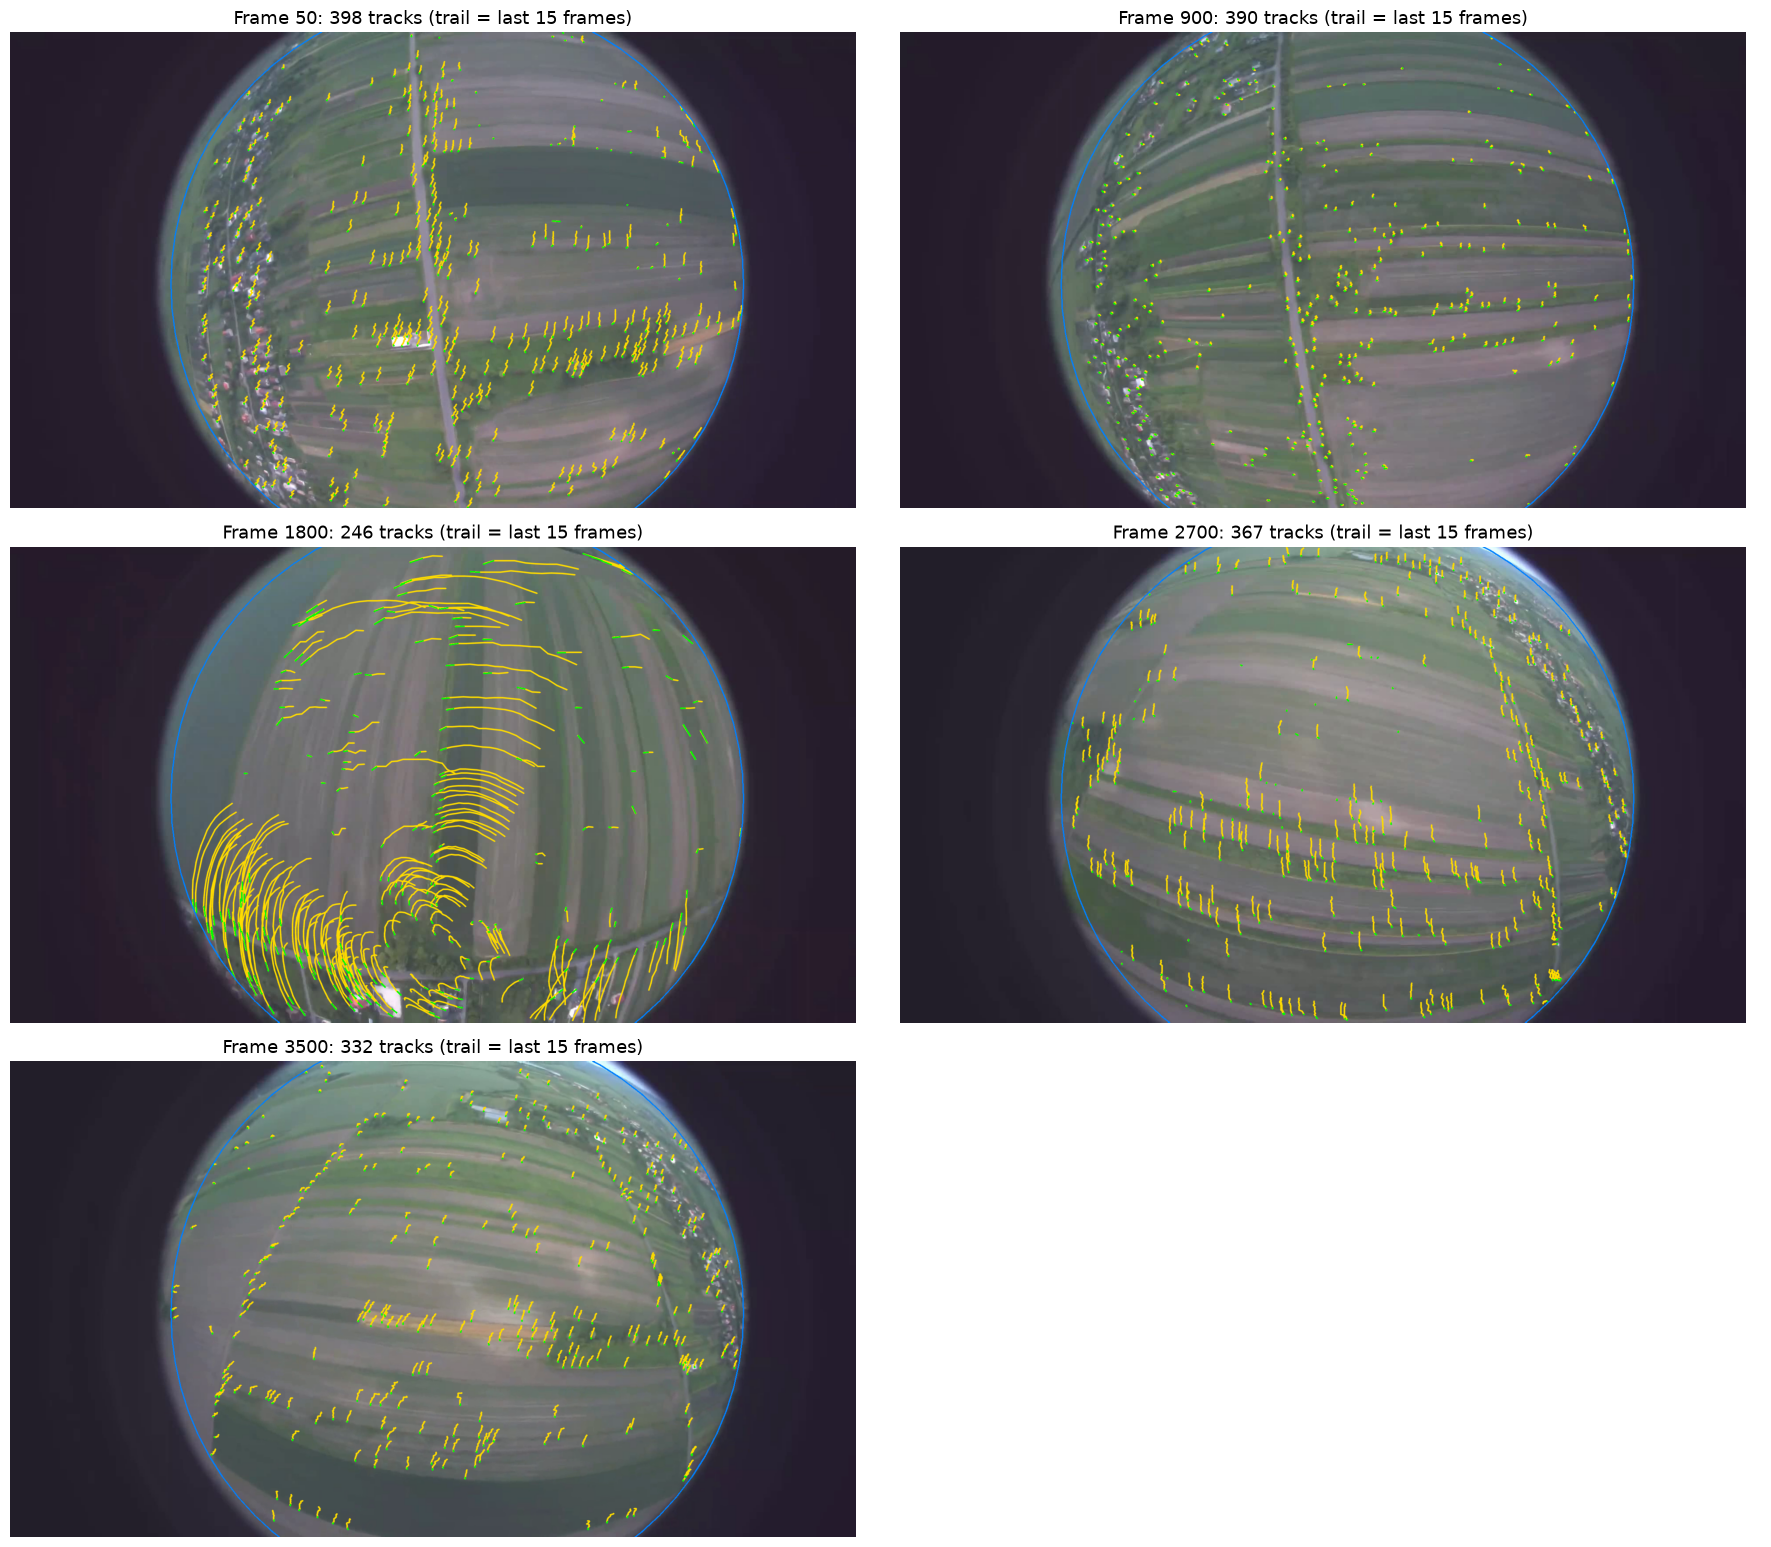

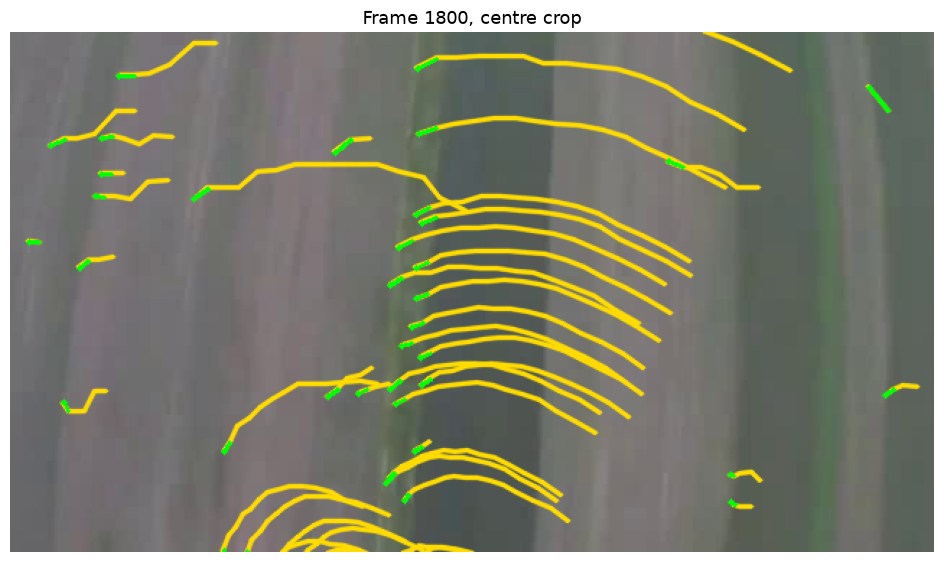

In [ ]:
# visual sanity check
snap_keys = sorted(snapshots)
n_cols = 2
n_rows = int(np.ceil(len(snap_keys) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5.2 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, fk in zip(axes, snap_keys):
    ax.imshow(cv.cvtColor(snapshots[fk], cv.COLOR_BGR2RGB))
    ax.set_title(f"Frame {fk}: {stats['tracked'][fk - 1]} tracks (trail = last {TRAIL_LEN} frames)")
    ax.axis("off")
for ax in axes[len(snap_keys):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


fk = snap_keys[len(snap_keys) // 2]
x0, y0 = int(K[0, 2]) - 320, int(K[1, 2]) - 180
plt.figure(figsize=(12, 6.75))
plt.imshow(cv.cvtColor(snapshots[fk][y0:y0 + 360, x0:x0 + 640], cv.COLOR_BGR2RGB))
plt.title(f"Frame {fk}, centre crop")
plt.axis("off")
plt.show()

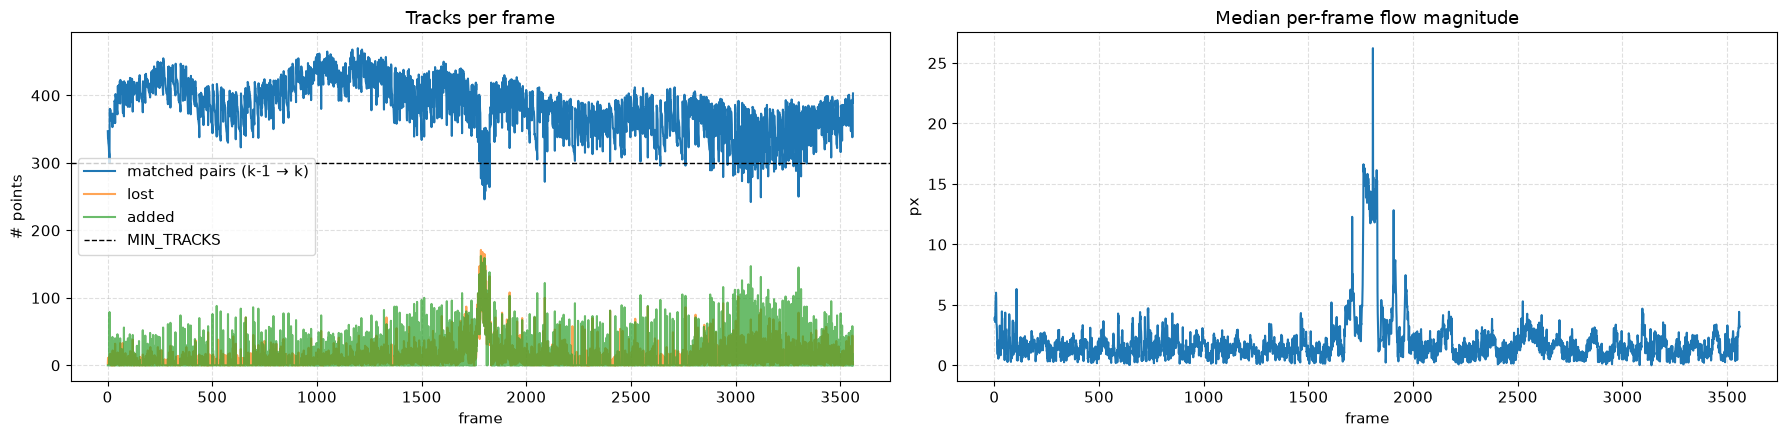

Pairs: 3560
Matches per pair: mean 384, min 242, max 470
Median flow per frame: 1.48 px
Lost per frame: mean 10.1; top-ups on 697 frames


In [18]:
# --- Tracking statistics ---
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
axes[0].plot(stats["frame"], stats["tracked"], label="matched pairs (k-1 → k)")
axes[0].plot(stats["frame"], stats["lost"], label="lost", alpha=0.7)
axes[0].plot(stats["frame"], stats["added"], label="added", alpha=0.7)
axes[0].axhline(MIN_TRACKS, color="k", ls="--", lw=1, label="MIN_TRACKS")
axes[0].set_xlabel("frame")
axes[0].set_ylabel("# points")
axes[0].set_title("Tracks per frame")
axes[0].legend()
axes[0].grid(True, ls="--", alpha=0.4)

axes[1].plot(stats["frame"], stats["median_flow"])
axes[1].set_xlabel("frame")
axes[1].set_ylabel("px")
axes[1].set_title("Median per-frame flow magnitude")
axes[1].grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

n_matches = np.array([len(p["pts_prev"]) for p in track_pairs])
print(f"Pairs: {len(track_pairs)}")
print(f"Matches per pair: mean {n_matches.mean():.0f}, min {n_matches.min()}, max {n_matches.max()}")
print(f"Median flow per frame: {np.nanmedian(stats['median_flow']):.2f} px")
print(f"Lost per frame: mean {stats['lost'].mean():.1f}; top-ups on {np.count_nonzero(stats['added'])} frames")

## camera motion

The camera looks almost straight down at flat ground, so two views of the ground are related by a homography $H = R + t\,n^T/d$, where $d$ is the camera height above the ground.

1. Accumulate tracks from a keyframe until the median displacement exceeds `MIN_PARALLAX` px
2. convert both point sets to undistorted normalized coordinates and keep only points within `MAX_ANGLE` of the optical axis; further out, the undistorted coordinates blow up and amplify tracking noise
3. Fit $H$ with RANSAC
4. `decomposeHomographyMat` gives up to 4 candidates $(R, t, n)$. Keep those where all inliers lie in front of both cameras, then the one whose plane normal is closest to the optical axis.
5. Chain the motions: $t$ comes in units of $d$, so each step is scaled by the current height estimate, which is updated from $n$ and the step itself
6. Frames between keyframes get linearly interpolated positions, so there is a pose for every frame. The evaluation aligns VO to GT on the first 500 poses, which is meant as the first 500 frames

In [ ]:
MAX_ANGLE = 60
RANSAC_PX = 1.5
MIN_PARALLAX = 15
MAX_GAP = 30
MIN_INLIERS = 30

In [ ]:
class PlaneOdometry:

    def __init__(self, K):
        self.f = K[0, 0]
        self.max_tan = np.tan(np.radians(MAX_ANGLE))
        self.R = np.eye(3)
        self.c = np.zeros(3)
        self.height = 1.0
        self.positions = [self.c.copy()]
        self.frame_indices, self.inliers = [], []
        self.kf_idx = 0
        self.kf_pts = {}
        self.failed = 0
        self.all_frames, self.all_times = [], []

    def estimate(self, pts_a, pts_b):
        if len(pts_a) < MIN_INLIERS:
            return None
        na = undistort_to_normalized(pts_a)
        nb = undistort_to_normalized(pts_b)
        keep = (np.linalg.norm(na, axis=1) < self.max_tan) & (np.linalg.norm(nb, axis=1) < self.max_tan)
        na, nb = na[keep], nb[keep]
        if len(na) < MIN_INLIERS:
            return None
        H, mask = cv.findHomography(na, nb, cv.RANSAC, RANSAC_PX / self.f)
        if H is None or mask.sum() < MIN_INLIERS:
            return None
        mask = mask.ravel().astype(bool)
        _, Rs, ts, ns = cv.decomposeHomographyMat(H, np.eye(3))
        visible = cv.filterHomographyDecompByVisibleRefpoints(Rs, ns, na[mask].reshape(-1, 1, 2).astype(np.float32), nb[mask].reshape(-1, 1, 2).astype(np.float32))
        if visible is None or len(visible) == 0:
            return None
        best = max(visible.ravel(), key=lambda i: ns[i][2, 0])
        return Rs[best], ts[best].ravel(), ns[best].ravel(), int(mask.sum())

    def step(self, pair):
        self.all_frames.append(pair["curr_idx"])
        self.all_times.append(pair["timestamp"])
        ids = pair["track_ids"].tolist()
        if pair["prev_idx"] == self.kf_idx:
            for tid, p in zip(ids, pair["pts_prev"]):
                self.kf_pts.setdefault(tid, p)
        cur = dict(zip(ids, pair["pts_curr"]))
        common = [tid for tid in cur if tid in self.kf_pts]
        pts_a = np.array([self.kf_pts[tid] for tid in common]).reshape(-1, 2)
        pts_b = np.array([cur[tid] for tid in common]).reshape(-1, 2)
        flow = np.median(np.linalg.norm(pts_b - pts_a, axis=1)) if common else 0.0
        if flow < MIN_PARALLAX and pair["curr_idx"] - self.kf_idx < MAX_GAP:
            return

        res = self.estimate(pts_a, pts_b)
        n_in = 0
        if res is None:
            self.failed += 1
        else:
            R, t, n, n_in = res
            move = -R.T @ t
            self.c = self.c + self.height * (self.R @ move)
            self.height *= 1 - n @ move
            self.R = self.R @ R.T

        self.positions.append(self.c.copy())
        self.frame_indices.append(pair["curr_idx"])
        self.inliers.append(n_in)
        self.kf_idx = pair["curr_idx"]
        self.kf_pts = cur

    def result(self):
        kf = [0] + self.frame_indices
        pos = np.array(self.positions)
        frames = np.array([f for f in self.all_frames if f <= kf[-1]])
        xyz = np.column_stack([np.interp(frames, kf, pos[:, i]) for i in range(3)])
        inliers = np.array(self.inliers)[np.searchsorted(kf, frames) - 1]
        times = np.array(self.all_times)[:len(frames)]
        return TrajectoryResult(timestamps=times.tolist(), positions=np.vstack([pos[:1], xyz]), inliers=inliers.tolist(), frame_indices=frames.tolist())

In [ ]:
odo = PlaneOdometry(K)
for pair in tqdm(track_pairs, desc="Pose", unit="pair"):
    odo.step(pair)
traj_result = odo.result()

gaps = np.diff([0] + odo.frame_indices)
print(f"Keyframes: {len(odo.frame_indices)}, mean gap {gaps.mean():.1f} frames, failed estimates: {odo.failed}")
print(f"Inliers per keyframe: median {np.median(odo.inliers):.0f}, min {np.min(odo.inliers)}")
print(f"Poses: {len(traj_result.frame_indices)} (keyframes plus interpolated frames in between)")
print(f"Final height: {odo.height:.3f} of the starting height")

## step 3

In [ ]:
# Your pipeline here. It must produce `traj_result` and write OVERLAY_VIDEO_PATH.
traj_result: TrajectoryResult = ...

## Evaluation

Do not modify. Checks the result format, plots the trajectory and inliers, renders the trajectory video, and compares against GT.

In [ ]:
assert isinstance(traj_result, TrajectoryResult), "traj_result must be a TrajectoryResult"
n = len(traj_result.frame_indices)
assert n > 0, "No poses recovered"
assert traj_result.positions.shape[0] == n + 1, "positions must have len(frame_indices) + 1 rows"
assert len(traj_result.inliers) == n and len(traj_result.timestamps) == n, "inliers/timestamps must match frame_indices"
assert OVERLAY_VIDEO_PATH.exists(), f"Overlay video not found: {OVERLAY_VIDEO_PATH}"
print(f"Recovered {n} poses")

plot_trajectory(traj_result)

In [ ]:
write_video_with_trajectory(
    OVERLAY_VIDEO_PATH,
    traj_result,
    output_path=TRAJECTORY_VIDEO_PATH,
    stride=5,
)

In [ ]:
analyze_trajectory(traj_result, GT_PATH)

## Summary

**Implementation choices:** _..._

**Parameter tuning:** _which parameters you tuned, what you tried, and the evidence from your run that justified the final values._

**Trajectory quality and overlay video:** _how close the result is to GT, where it drifts or fails, and why._